# Notebook 04 - Random Forest Classifier on Autoencoder Features

This notebook trains a **Random Forest classifier** on latent features extracted by the trained encoder.

**Stages:**
1. Extract latent features from encoder
2. Flatten to pixel-wise feature vectors
3. Train Random Forest
4. Evaluate - Accuracy, Precision, Recall, F1
5. Confusion Matrix visualization

## Step 1: Imports & Setup

In [1]:
import os, sys
# Set project root path cleanly
ROOT_DIR = os.path.abspath('..') if os.path.exists('../config.json') else os.path.abspath('.')
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
import seaborn as sns
import joblib
from dataset import Sen1FloodsDataset, get_train_val_test_splits
from models import ConvAutoencoder
from utils import set_seed, load_config

config = load_config(os.path.join(ROOT_DIR, 'config.json'))
set_seed(config['training']['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

print(f'Using device: {device}')


Using device: cpu


## Step 2: Load Encoder & Extract Latent Features

In [2]:
models_dir = os.path.join(ROOT_DIR, 'models')
autoencoder = ConvAutoencoder(dropout_rate=config['model']['dropout_rate']).to(device)
autoencoder.load_state_dict(torch.load(os.path.join(models_dir, 'best_autoencoder.pth'), weights_only=True))
autoencoder.eval()

S1_DIR = os.path.join(ROOT_DIR, config['data']['s1_dir'])
LABEL_DIR = os.path.join(ROOT_DIR, config['data']['label_dir'])
TARGET_SIZE = tuple(config['data']['target_size'])

s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])
file_pairs = list(zip(
    [os.path.join(S1_DIR, f) for f in s1_files],
    [os.path.join(LABEL_DIR, f) for f in label_files]
))

train_idx, val_idx, test_idx = get_train_val_test_splits(len(file_pairs), config['data']['split_ratio'])
train_pairs = [file_pairs[i] for i in train_idx]
test_pairs  = [file_pairs[i] for i in test_idx]

def extract_features(pairs, max_pixels=10000):
    dataset = Sen1FloodsDataset(pairs, target_size=TARGET_SIZE)
    loader = DataLoader(dataset, batch_size=1, shuffle=False)
    all_features, all_labels = [], []
    with torch.no_grad():
        for img, label in loader:
            img = img.to(device)
            _, latent = autoencoder(img)
            upsampled = F.interpolate(latent, size=TARGET_SIZE, mode='bilinear', align_corners=False)
            feats = upsampled.squeeze(0).cpu().numpy()
            feats = feats.reshape(feats.shape[0], -1).T
            lbl = label.squeeze(0).numpy().flatten()
            valid = lbl != -1
            all_features.append(feats[valid])
            all_labels.append(lbl[valid])
    feats = np.concatenate(all_features)
    labels = np.concatenate(all_labels).astype(int)
    if len(labels) > max_pixels:
        idx = np.random.choice(len(labels), max_pixels, replace=False)
        feats, labels = feats[idx], labels[idx]
    return feats, labels

print('Extracting training features...')
X_train, y_train = extract_features(train_pairs)
print(f'Train features shape: {X_train.shape}')

print('Extracting test features...')
X_test, y_test = extract_features(test_pairs)
print(f'Test features shape: {X_test.shape}')


Extracting training features...
Train features shape: (10000, 256)
Extracting test features...
Test features shape: (10000, 256)


## Step 3: Train Random Forest Classifier

In [3]:
print('Training Random Forest Classifier...')
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    n_jobs=-1,
    random_state=42
)
rf_model.fit(X_train, y_train)
models_dir = os.path.join(ROOT_DIR, 'models')
joblib.dump(rf_model, os.path.join(models_dir, 'random_forest.pkl'))
print('Random Forest trained and saved successfully!')


Training Random Forest Classifier...
Random Forest trained and saved successfully!


## Step 4: Evaluate Performance

=== Random Forest Performance ===
Accuracy:  0.9991
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000

Classification Report:
              precision    recall  f1-score   support

   Non-Flood       1.00      1.00      1.00      9991
       Flood       0.00      0.00      0.00         9

    accuracy                           1.00     10000
   macro avg       0.50      0.50      0.50     10000
weighted avg       1.00      1.00      1.00     10000



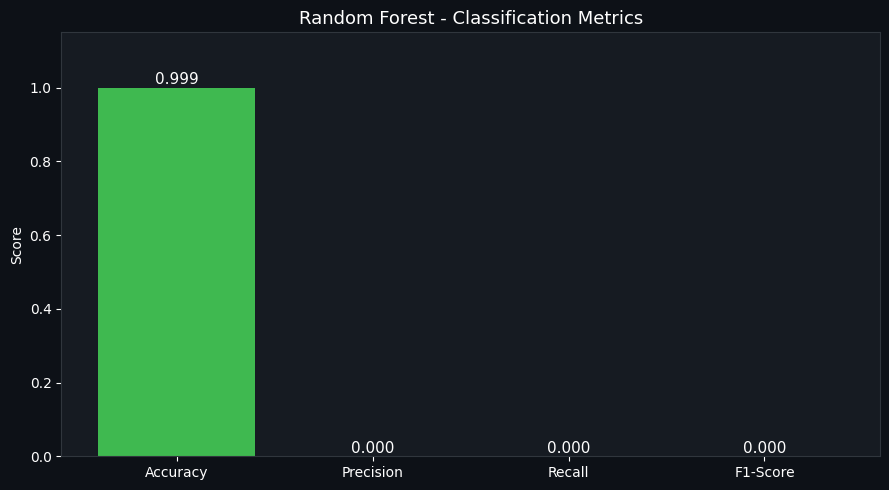

In [4]:
y_pred = rf_model.predict(X_test)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec  = recall_score(y_test, y_pred, zero_division=0)
f1   = f1_score(y_test, y_pred, zero_division=0)

print('=== Random Forest Performance ===')
print(f'Accuracy:  {acc:.4f}')
print(f'Precision: {prec:.4f}')
print(f'Recall:    {rec:.4f}')
print(f'F1-Score:  {f1:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Non-Flood', 'Flood']))

metrics = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(metrics.keys(), metrics.values(), color=['#3fb950','#58a6ff','#f78166','#d2a8ff'])
for bar, val in zip(bars, metrics.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.3f}', ha='center', fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_title('Random Forest - Classification Metrics', fontsize=13)
ax.set_ylabel('Score')
plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/rf_metrics.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 5: Confusion Matrix

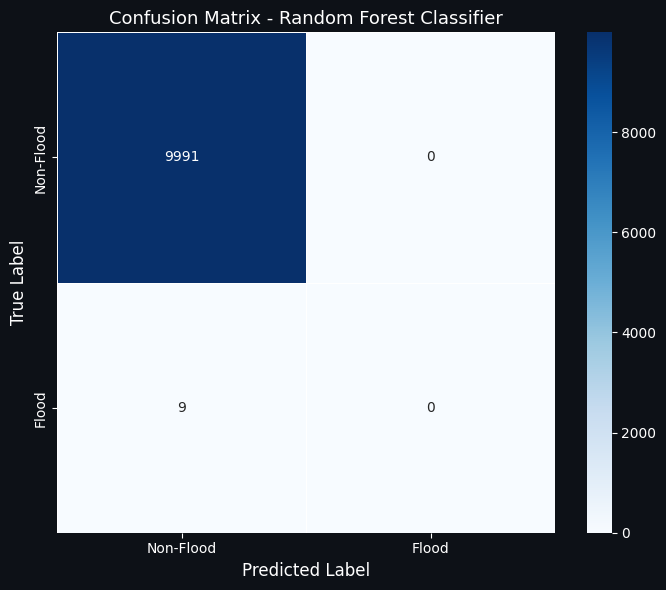

In [5]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Flood', 'Flood'],
            yticklabels=['Non-Flood', 'Flood'],
            ax=ax, linewidths=0.5, cbar=True)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Confusion Matrix - Random Forest Classifier', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/rf_confusion_matrix.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
